<b>Vamos a generar los malladores de preforma</b>

Importo las librerías

In [3]:
import numpy as np
import matplotlib as plt


<b>CAÑO</b>

In [24]:
D_cilindro = 200  # diámetro de cilindro
L_cilindro = 500  # longitud del cilindro
N_divisiones = 25
# estas son las divisiones circunferenciaes que voy a tener en el cilindro
N_divisiones_L = int(L_cilindro // (np.pi * D_cilindro / N_divisiones))

# MATRIZ DE NODOS
matriz = np.arange(N_divisiones * N_divisiones_L).reshape(N_divisiones_L, N_divisiones)

# ARMO LA MATRIZ DE ELEMENTOS
# creo la matriz de ceros + una columna por ser cíclica
buffer = np.zeros((N_divisiones_L, N_divisiones + 1))
# ingreso los valores de la matriz original
buffer[:, 0:N_divisiones] = matriz
# ingreso los valores a la última fila del buffer
buffer[:, N_divisiones] = matriz[:, 0]

elementos = []
for i in range(buffer.shape[0] - 1):
    for j in range(buffer.shape[1] - 1):
        elemento = buffer[i : i + 2, j : j + 2]
        # print(elemento)
        elementos.append(elemento.flatten())
elementos = np.array(elementos)
#print(elementos)

#Armo la matriz de coordenadas de los nodos
buffer_nodos = matriz.flatten()  # transformo la matriz en un vector
print(buffer_nodos)
for i in range(len(buffer_nodos)):
    # calculo el ángulo de cada nodo
    angulo = (buffer_nodos[i] % N_divisiones) * (2 * np.pi / N_divisiones)
    # calculo la coordenada x del nodo
    x = D_cilindro / 2 * np.cos(angulo)
    # calculo la coordenada y del nodo
    y = D_cilindro / 2 * np.sin(angulo)
    # calculo la coordenada z del nodo
    z = (buffer_nodos[i] // N_divisiones) * (L_cilindro / N_divisiones_L)
    # guardo las coordenadas en la matriz de nodos
    if i == 0:
        nodos = np.array([[x, y, z]])
    else:
        nodos = np.vstack((nodos, [x, y, z]))

#print(nodos)

[  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125
 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143
 144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161
 162 163 164 165 166 167 168 169 170 171 172 173 174 175 176 177 178 179
 180 181 182 183 184 185 186 187 188 189 190 191 192 193 194 195 196 197
 198 199 200 201 202 203 204 205 206 207 208 209 210 211 212 213 214 215
 216 217 218 219 220 221 222 223 224 225 226 227 228 229 230 231 232 233
 234 235 236 237 238 239 240 241 242 243 244 245 24

<b> GRAFICADOR DE CAÑO</b>

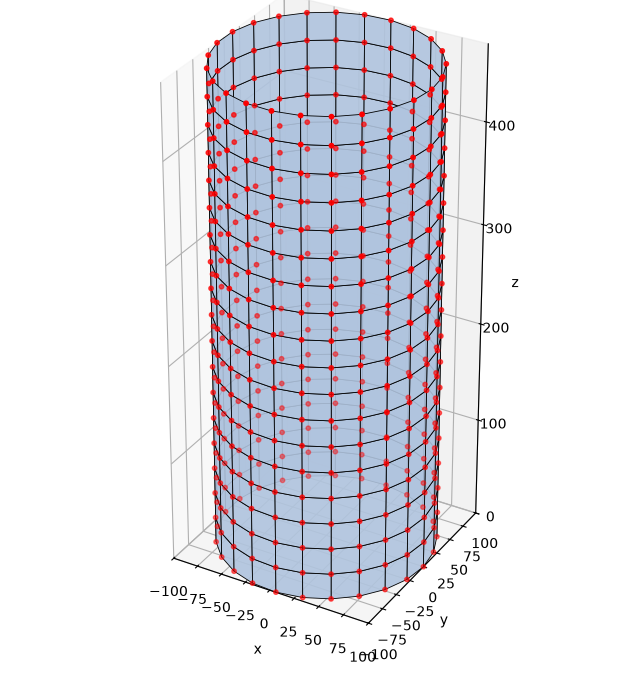

In [25]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# conectividad como enteros y en orden perimetral
elementos = elementos.astype(int)[:, [0, 1, 3, 2]]

# coordenadas de cada vértice de cada cara: (N_elementos, 4, 3)
caras = nodos[elementos]

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")

coleccion = Poly3DCollection(
    caras,
    facecolors="lightsteelblue",
    edgecolors="k",
    linewidths=0.6,
    alpha=0.9,
)
ax.add_collection3d(coleccion)

# nodos (opcional)
ax.scatter(nodos[:, 0], nodos[:, 1], nodos[:, 2], color="r", s=10)

# límites y proporción
R = D_cilindro / 2
ax.set_xlim(-R, R)
ax.set_ylim(-R, R)
ax.set_zlim(0, nodos[:, 2].max())
ax.set_box_aspect((2 * R, 2 * R, nodos[:, 2].max()))

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
plt.show()

<b>TEE</b>

In [ ]:
OD_1 = 200  # OD straight
OD_2 = 100  # OD derivación
H_1=200 # de entrada a intersección
H_2=400 # de intersección a salida lateral
H_3=350 # de intersección a salida final
Alpha_2 = 90 # ángulo de  derivación



